# Sedov-Taylor blast waves against the exact solution

A point explosion of energy E in a cold uniform gas drives a self-similar blast wave with shock
radius R_s = (E t^2 / (alpha rho0))^(1/(j+2)), j = 2 cylindrical, 3 spherical (Sedov 1959). The
exact profiles come from `luna.hydro.exact_sedov` (Kamm 2000 closed form; alpha checked against
Kamm & Timmes 2007).

1. **2D (cylindrical), off-axis**: the blast centred at a point that is no cell centre, corner or
   symmetry point of the grid (the setup of `tests/test_hydro_hard_sedov_offaxis.py`), gamma = 1.4,
   periodic unit box, 64² and 128². Compared: the angle-mean shock radius against R_s (in cells),
   its scatter over 32 angle wedges, and L1(rho)/rho_2 in the band 0.4-1.2 R_s.
2. **3D**, the registered `Sedov-Blast-3D` problem at 32³ (gamma = 5/3): shock radius at four times
   and the density and pressure profiles behind the shock.

Small grids: the test runs the 2D case to 2048² on a GPU and the 3D case at 128³-256³.

Runtime: about 20 seconds on four CPU cores (an A100 node's CPU cores via SLURM, JAX on the CPU), including JAX start-up and compilation, which dominate.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")   # this notebook is sized for a CPU; unset it to use a GPU

import contextlib, io, time
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from luna import Config, launch


def run(cfg, **state):
    """launch(cfg, **state), as `python main.py` runs it (state: U0= or ic=, an initial state of our own),
    with its log kept out of the notebook; (RunResult, wall s)."""
    t0 = time.time()
    with contextlib.redirect_stdout(io.StringIO()):
        res = launch(cfg, **state)
    return res, time.time() - t0


# FP64, PLM, HLLC, quiet: the settings of LUNA's accuracy tests
QUIET = dict(enable_x64=True, ORDER=1, LIMITER=0, riemann_solver="hllc", PLOT_AFTER_SIM=False,
             output_cadence=10**6, diag_interval=10**6, enable_checkpointing=False, clear_output_dir=True)
BASE = replace(Config(), **QUIET)

**A custom initial state through the run path.** LUNA's registered problems (`test_problem`) fix
their initial states. A state of our own goes to `launch(cfg, U0=U)`: `U` holds the conserved
variables on the whole grid in the run's own dimension, `(3, Nx)` in 1D (rho, rho vx, E),
`(4, Nx, Ny)` in 2D, `(5, Nx, Ny, Nz)` in 3D, energy last; a shape that does not fit the config is
refused. It takes the path `python main.py` takes (`luna/ic_generation/user_ic.py`), sharded like a
registered problem; `test_problem` then only names the run.

In [2]:
import math
from luna.hydro import exact_sedov as se

G2, RHO0, P_BG, E0, T = 1.4, 1.0, 1e-5, 1.0, 0.09      # as tests/test_hydro_hard_sedov_offaxis.py
SIGMA, XC, NA = 0.004, (0.4637, 0.5219), 32             # deposit width, blast centre, angle wedges


def initial2d(n):
    """Ambient gas at rest plus E0 as the exact cell averages of a narrow Gaussian at XC."""
    edges = np.arange(n + 1) / n
    w = []
    for c in XC:
        d = np.diff([0.5 * math.erf((e - c) / (math.sqrt(2.0) * SIGMA)) for e in edges])
        w.append(d / d.sum())
    U = np.zeros((4, n, n))                       # rho, rho vx, rho vy, E
    U[0] = RHO0
    U[3] = P_BG / (G2 - 1) + E0 * np.multiply.outer(*w) * n * n
    return U


def crossing(prof, x, level):
    """Outermost x beyond the peak where prof falls through level (linear between bins)."""
    i0 = int(np.argmax(prof))
    j = i0 + int(np.argmax(prof[i0:] < level))
    return x[j - 1] + (level - prof[j - 1]) / (prof[j] - prof[j - 1]) * (x[j] - x[j - 1])


def analyse2d(rho, n):
    """Shock radius per angle wedge (half-cell radial bins), its mean and scatter, L1 in the band."""
    dx = 1.0 / n
    x = (np.arange(n) + 0.5) / n
    X, Y = np.meshgrid(x - XC[0], x - XC[1], indexing="ij")
    r, th = np.hypot(X, Y), np.arctan2(Y, X)
    Rs = se.solution(np.zeros(1), T, E0, RHO0, G2, j=2)[3]
    k = np.minimum(((th + np.pi) / (2 * np.pi) * NA).astype(int), NA - 1)
    nr = int(1.5 * Rs / (0.5 * dx)) + 1
    m = r < 1.5 * Rs
    idx = k[m] * nr + (r[m] / (0.5 * dx)).astype(int)
    cnt = np.bincount(idx, minlength=NA * nr).reshape(NA, nr)
    tot = np.bincount(idx, rho[m], minlength=NA * nr).reshape(NA, nr)
    rc = (np.arange(nr) + 0.5) * 0.5 * dx
    R = []
    for w in range(NA):
        ok = cnt[w] > 0
        prof = tot[w][ok] / cnt[w][ok]
        R.append(crossing(prof, rc[ok], 0.5 * (prof.max() + RHO0)))
    R = np.array(R)
    band = (r > 0.4 * Rs) & (r < 1.2 * Rs)
    rho2 = RHO0 * (G2 + 1) / (G2 - 1)
    L1 = float(np.mean(np.abs(rho[band] - se.solution(r[band], T, E0, RHO0, G2, j=2)[0]))) / rho2
    return dict(dR=(R.mean() - Rs) / dx, sR=R.std() / Rs, L1=L1, Rs=Rs), r

In [3]:
base2 = replace(BASE, test_problem="Sedov-2D-Off-Axis", SPATIAL_DIMENSION=2,
                Lx=1.0, Ly=1.0, BOUNDARY=0, gamma=G2, t_end=T, write_snapshots=False)
# measured by the test at N = 64 (CPU, FP64, minmod): dR = 0.902 cells, sR = 0.0176, L1 = 0.0571
res2 = {}
for n in (64, 128):
    res, wall = run(replace(base2, Nx=n, Ny=n, output_dir="snapshots/nb04/run2d"), U0=initial2d(n))
    rho = np.asarray(res.extra["U"], np.float64)[0]
    m, r = analyse2d(rho, n)
    res2[n] = (rho, r, m)
    print(f"N={n:4d}: steps {res.n_steps}, mean R - R_s = {m['dR']:+.3f} cells, "
          f"scatter over angle {m['sR']:.2e} R_s, L1(rho)/rho2 = {m['L1']:.4f}   ({wall:.1f} s)")

N=  64: steps 264, mean R - R_s = +0.903 cells, scatter over angle 1.76e-02 R_s, L1(rho)/rho2 = 0.0571   (3.1 s)


N= 128: steps 650, mean R - R_s = +0.951 cells, scatter over angle 2.39e-03 R_s, L1(rho)/rho2 = 0.0363   (4.0 s)


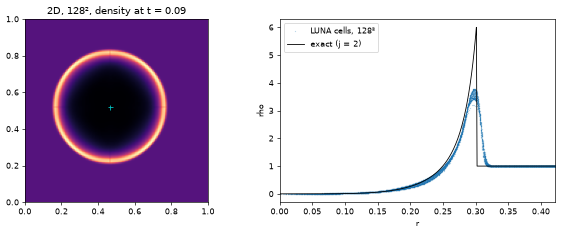

In [4]:
rho, r, m = res2[128]
rr = np.linspace(0, 1.4 * m["Rs"], 400)
fig, ax = plt.subplots(1, 2, figsize=(10, 4), dpi=60)
ax[0].imshow(rho.T, origin="lower", extent=(0, 1, 0, 1), cmap="magma")
ax[0].plot(*XC, "c+"); ax[0].set_title("2D, 128², density at t = 0.09")
ax[1].plot(r.ravel(), rho.ravel(), ".", ms=1, alpha=0.3, label="LUNA cells, 128²")
ax[1].plot(rr, se.solution(rr, T, E0, RHO0, G2, j=2)[0], "k-", lw=1, label="exact (j = 2)")
ax[1].set_xlim(0, 1.4 * m["Rs"]); ax[1].set_xlabel("r"); ax[1].set_ylabel("rho"); ax[1].legend()
fig.tight_layout()

## 3D: the registered `Sedov-Blast-3D`

Code units, E = 1 in the 2x2x2 cells at the box centre (`r_blast = 1.24` cells, their volume),
ambient rho = 1, p = 1e-4 (Mach ~ 20 at the end), outflow boundaries. The injected energy is read
back from the t = 0 snapshot.

In [5]:
from luna.ic_generation import sedov3d
from luna.file_io.read_snapshot import read_snapshot
import glob

n3, T3, G3 = 32, 0.05, 5.0 / 3.0
cfg3 = replace(BASE, test_problem="Sedov-Blast-3D", SPATIAL_DIMENSION=3,
               Nx=n3, Ny=n3, Nz=n3, Lx=1.0, Ly=1.0, Lz=1.0, BOUNDARY=1, gamma=G3,
               problem=sedov3d.Params(E=1.0, rho_bg=1.0, p_bg=1e-4, r_blast=1.24),
               t_end=T3, time_bet_snaps=T3 / 4, output_dir="snapshots/nb04/sedov3d")
res, wall = run(cfg3)
snaps = [read_snapshot(d) for d in sorted(glob.glob(f"{cfg3.output_dir}/snapdir_*"))]
dx = 1.0 / n3
x = (np.arange(n3) + 0.5) * dx - 0.5
r3 = np.sqrt(x[:, None, None] ** 2 + x[None, :, None] ** 2 + x[None, None, :] ** 2)
s0 = snaps[0]
p_bg = float(s0["P"].min())
E = float(np.sum(s0["P"] / (G3 - 1) - p_bg / (G3 - 1)) * dx ** 3)   # at rest at t = 0
print(f"{res.n_steps} steps, {wall:.1f} s; injected E = {E:.6f}")


def shock_radius(rho, rho0=1.0):
    """Outermost radius where the shell-averaged rho falls through (peak + rho0) / 2."""
    edges = np.arange(0.0, r3.max() + dx, 0.5 * dx)
    k = np.digitize(r3.ravel(), edges) - 1
    cnt = np.bincount(k, minlength=edges.size)
    prof = np.bincount(k, rho.ravel(), minlength=edges.size) / np.maximum(cnt, 1)
    rc = 0.5 * (edges[:-1] + edges[1:])
    ok = cnt[:rc.size] > 0
    return crossing(prof[:rc.size][ok], rc[ok], 0.5 * (prof[:rc.size][ok].max() + rho0))


for s in snaps[1:]:
    R_ex = se.solution(np.zeros(1), s["t"], E, 1.0, G3)[3]
    print(f"t = {s['t']:.4f}: R = {shock_radius(s['rho']):.4f}, exact {R_ex:.4f}, "
          f"difference {(shock_radius(s['rho']) - R_ex) / dx:+.2f} cells")

129 steps, 4.5 s; injected E = 1.001697
t = 0.0125: R = 0.2197, exact 0.1996, difference +0.64 cells
t = 0.0250: R = 0.2832, exact 0.2634, difference +0.63 cells
t = 0.0375: R = 0.3347, exact 0.3098, difference +0.80 cells
t = 0.0500: R = 0.3726, exact 0.3476, difference +0.80 cells


behind the shock at t = 0.050: L1(rho)/rho2 = 0.0798, L1(p)/p2 = 0.0859


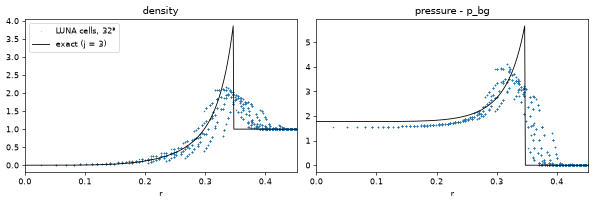

In [6]:
s = snaps[-1]
rho_ex, _, p_ex, Rs = se.solution(r3, s["t"], E, 1.0, G3)
inside = r3 < Rs
Rdot = 0.4 * Rs / s["t"]
rho2, p2 = (G3 + 1) / (G3 - 1), 2 * Rdot ** 2 / (G3 + 1)
e_rho = float(np.mean(np.abs(s["rho"] - rho_ex)[inside])) / rho2
e_p = float(np.mean(np.abs(s["P"] - p_ex - p_bg)[inside])) / p2
print(f"behind the shock at t = {s['t']:.3f}: L1(rho)/rho2 = {e_rho:.4f}, L1(p)/p2 = {e_p:.4f}")
rr = np.linspace(0, 1.3 * Rs, 400)
ex = se.solution(rr, s["t"], E, 1.0, G3)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), dpi=60)
for a, f, e, name in ((ax[0], s["rho"], ex[0], "density"), (ax[1], s["P"] - p_bg, ex[2], "pressure - p_bg")):
    a.plot(r3.ravel(), f.ravel(), ".", ms=1, alpha=0.3, label="LUNA cells, 32³")
    a.plot(rr, e, "k-", lw=1, label="exact (j = 3)")
    a.set_xlim(0, 1.3 * Rs); a.set_xlabel("r"); a.set_title(name)
ax[0].legend()
fig.tight_layout()

**What this shows.** 2D: at 64² the mean shock radius (+0.90 cells off R_s) and L1(rho)/rho2 = 0.0571 are the test's values; at 128² the scatter of the shock radius over angle falls from 1.8e-2 to 2.4e-3 R_s and L1 to 0.036. 3D at 32³: the shock radius is 0.6-0.8 cells beyond the exact one at all four times (R_s is 11 cells at the end), L1(rho)/rho2 = 0.080 and L1(p)/p2 = 0.086 behind the shock. A coarse grid; the test's 2D ladder reaches 2048².

Status (docs/CLAIMS.md): 2D off-axis Sedov *validated*, `tests/test_hydro_hard_sedov_offaxis.py:219, :243`;
3D Sedov shock radius and profile *shown* (regression only: scalar checks),
`tests/test_hydro_accuracy_sedov.py:69`.